# Cálculos y comprobaciones del Capítulo 6
**Construcción y análisis de códigos tipo CSS**

Este notebook reúne todos los cálculos a los que hace referencia el Capítulo 6 y genera sus dos gráficas. Está organizado siguiendo las secciones del capítulo:

| Parte del notebook | Sección del capítulo |
|---|---|
| 1. Funciones | 6.1 Metodología (y Anexo) |
| 2. Validación | 6.2 Validación |
| 3. Parámetros de las familias | 6.3 Parámetros de las familias construidas |
| 4. Comportamiento y gráficas | 6.4 Comportamiento asintótico |
| 5. Cotas cuánticas | 6.5 Comparación con las cotas cuánticas |
| 6. Códigos de la literatura | 6.6 Comparación con la literatura |

Dependencias: `numpy`, `pandas` y `matplotlib`. La ejecución completa toma alrededor de un minuto.

In [ ]:
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## 1. Funciones (sección 6.1 y Anexo)
Las funciones son las mismas del programa del Anexo. Todas las operaciones se realizan sobre $\mathbb{F}_2$.

### 1.1 Álgebra lineal sobre $\mathbb{F}_2$
Las filas se representan como enteros, de modo que la suma módulo 2 de dos filas es la operación XOR. El rango se obtiene por eliminación gaussiana.

In [ ]:
def fila_a_entero(fila):
    """Representa una fila binaria como un entero (bit j = entrada j)."""
    return sum(1 << j for j, b in enumerate(fila) if b)


def base_reducida(M):
    """Base del espacio fila de M, guardada por su bit principal.
    Se construye por eliminación gaussiana sobre F_2."""
    base = {}
    for fila in M:
        v = fila_a_entero(fila)
        while v:
            b = v.bit_length() - 1          # bit principal de v
            if b not in base:
                base[b] = v
                break
            v ^= base[b]                     # se reduce con la fila de la base
    return base


def rango_f2(M):
    """Rango de M sobre F_2."""
    return len(base_reducida(M))


def en_espacio_fila(base, v):
    """Indica si el entero v pertenece al espacio generado por la base."""
    while v:
        b = v.bit_length() - 1
        if b not in base:
            return False
        v ^= base[b]
    return True


def base_nucleo(H):
    """Base del código C = {x : H x^T = 0} (núcleo de H)."""
    H = np.array(H, dtype=np.uint8) % 2
    m, n = H.shape
    A = H.copy()
    pivotes, r = [], 0
    for c in range(n):
        filas = np.nonzero(A[r:, c])[0]
        if filas.size == 0:
            continue
        p = r + filas[0]
        A[[r, p]] = A[[p, r]]
        for i in np.nonzero(A[:, c])[0]:
            if i != r:
                A[i] ^= A[r]
        pivotes.append(c)
        r += 1
        if r == m:
            break
    libres = [c for c in range(n) if c not in pivotes]
    base = []
    for f in libres:
        x = np.zeros(n, dtype=np.uint8)
        x[f] = 1
        for i, c in enumerate(pivotes):
            x[c] = A[i, f]
        base.append(x)
    return base

### 1.2 Matrices de paridad de las familias
$H_L$ (código de repetición periódico), $H_r$ (Hamming) y $H(p)$ (QC-LDPC $(3,4)$-regular, bloque $(a,b)$ igual a $P^{ab \bmod p}$).

In [ ]:
def matriz_repeticion(L):
    """Código de repetición periódico: la fila i revisa los bits i e i+1 (mod L)."""
    H = np.zeros((L, L), dtype=np.uint8)
    for i in range(L):
        H[i, i] = 1
        H[i, (i + 1) % L] ^= 1
    return H


def matriz_hamming(r):
    """H_r: sus columnas son los números 1, ..., 2^r - 1 escritos en binario."""
    n = 2 ** r - 1
    return np.array([[(c >> (r - 1 - i)) & 1 for c in range(1, n + 1)]
                     for i in range(r)], dtype=np.uint8)


def permutacion_circulante(p, e):
    """P^e: matriz p x p con unos en las posiciones (i, i+e mod p)."""
    P = np.zeros((p, p), dtype=np.uint8)
    for i in range(p):
        P[i, (i + e) % p] = 1
    return P


def matriz_qc(p):
    """H(p): bloque (a, b) igual a P^(ab mod p), con a = 0,1,2 y b = 0,1,2,3."""
    return np.vstack([np.hstack([permutacion_circulante(p, (a * b) % p)
                                 for b in range(4)]) for a in range(3)])

### 1.3 Producto de hipergrafos
$H_X = (H_1\otimes I_{n_2} \mid I_{m_1}\otimes H_2^T)$, $\quad H_Z = (I_{n_1}\otimes H_2 \mid H_1^T\otimes I_{m_2})$.

In [ ]:
def producto_hipergrafos(H1, H2):
    """H_X = (kron(H1, I) | kron(I, H2^T)),  H_Z = (kron(I, H2) | kron(H1^T, I))."""
    m1, n1 = H1.shape
    m2, n2 = H2.shape
    I = lambda k: np.eye(k, dtype=np.uint8)
    HX = np.hstack([np.kron(H1, I(n2)), np.kron(I(m1), H2.T)]) % 2
    HZ = np.hstack([np.kron(I(n1), H2), np.kron(H1.T, I(m2))]) % 2
    return HX.astype(np.uint8), HZ.astype(np.uint8)

### 1.4 Distancia de un código lineal
Menor número de columnas de la matriz de paridad que suman el vector nulo. Si la dimensión del código es pequeña ($k\le 20$) se recorren directamente sus $2^k$ palabras de código, lo que da el mismo resultado.

In [ ]:
def distancia_clasica(H, peso_max=12):
    """Menor número de columnas de H que suman el vector nulo, es decir,
    el menor peso de una palabra de código no nula.

    - Si la dimensión del código es pequeña (k <= 20), se recorren las
      2^k palabras de código y se toma el menor peso.
    - En otro caso, se prueban conjuntos de w = 1, 2, ... columnas,
      dividiendo cada conjunto en dos mitades (encuentro a mitad de camino).
    Devuelve None si el código es trivial (convención d = infinito)."""
    H = np.array(H, dtype=np.uint8) % 2
    base = base_nucleo(H)
    k = len(base)
    if k == 0:
        return None
    if k <= 20:
        B = np.array(base, dtype=np.int64)
        mejor = H.shape[1]
        for coef in range(1, 2 ** k):
            elegidas = [i for i in range(k) if (coef >> i) & 1]
            peso = int((B[elegidas].sum(axis=0) % 2).sum())
            mejor = min(mejor, peso)
        return mejor
    columnas = [fila_a_entero(H[:, j]) for j in range(H.shape[1])]
    sumas = {0: {0}}

    def sumas_de(t):
        if t not in sumas:
            s = set()
            for comb in combinations(columnas, t):
                x = 0
                for c in comb:
                    x ^= c
                s.add(x)
            sumas[t] = s
        return sumas[t]

    for w in range(1, peso_max + 1):
        a, b = (w + 1) // 2, w // 2
        if a == b:
            # dos mitades distintas con la misma suma dan una palabra de peso <= w
            conteo = {}
            for comb in combinations(range(len(columnas)), a):
                x = 0
                for j in comb:
                    x ^= columnas[j]
                conteo[x] = conteo.get(x, 0) + 1
                if conteo[x] > 1:
                    return w
        elif sumas_de(a) & sumas_de(b):
            return w
    raise ValueError("distancia mayor que peso_max")

### 1.5 Distancia cuántica por búsqueda directa
Solo para códigos pequeños: menor peso de un vector que no es detectado y que no pertenece al estabilizador. Se usa únicamente en la validación.

In [ ]:
def distancia_cuantica_directa(HX, HZ, peso_max):
    """Menor peso de un error lógico: un vector v con H_Z v^T = 0 que no
    pertenece al espacio fila de H_X (tipo X), o viceversa (tipo Z)."""
    def un_tipo(Hker, Hestab):
        base_estab = base_reducida(Hestab)
        cols = [fila_a_entero(Hker[:, j]) for j in range(Hker.shape[1])]
        for w in range(1, peso_max + 1):
            for comb in combinations(range(len(cols)), w):
                s = 0
                for j in comb:
                    s ^= cols[j]
                if s == 0:                                  # v está en el núcleo
                    v = sum(1 << j for j in comb)
                    if not en_espacio_fila(base_estab, v):  # y no es estabilizador
                        return w
        return None
    return min(un_tipo(HZ, HX), un_tipo(HX, HZ))

### 1.6 Parámetros del código HGP con $H_1=H_2=H$
Calcula $n$, $k$ y $d$. En cada llamada comprueba que $H_XH_Z^T=0$ y que el valor de $k$ obtenido con los rangos, $k=n-\operatorname{rank}(H_X)-\operatorname{rank}(H_Z)$, coincide con la fórmula $k=k_1^2+(k_1^T)^2$.

In [ ]:
def parametros_hgp(H):
    m, n = H.shape
    HX, HZ = producto_hipergrafos(H, H)
    assert not ((HX.astype(int) @ HZ.T.astype(int)) % 2).any()   # H_X H_Z^T = 0
    rH = rango_f2(H)
    k1, k1T = n - rH, m - rH
    N = HX.shape[1]
    K = N - rango_f2(HX) - rango_f2(HZ)          # k a partir de los rangos
    assert K == k1 * k1 + k1T * k1T               # coincide con la fórmula
    d1 = distancia_clasica(H)
    d1T = distancia_clasica(H.T) if k1T > 0 else None
    D = min(x for x in (d1, d1T) if x is not None)
    pesos = HX.sum(axis=1).tolist() + HZ.sum(axis=1).tolist()
    return dict(n1=n, m1=m, rango=rH, k1=k1, k1T=k1T, d1=d1, d1T=d1T,
                N=N, K=K, D=D, peso_min=min(pesos), peso_max=max(pesos),
                HX=HX, HZ=HZ)

### 1.7 Comprobación rápida de las matrices
Se muestran $H_3$ (debe coincidir con la matriz del ejemplo del Capítulo 1) y la matriz de exponentes de $H(5)$ (debe coincidir con la del Capítulo 1).

In [ ]:
print("H_3 =\n", matriz_hamming(3))
print("\nMatriz de exponentes de H(5):")
print(np.array([[(a * b) % 5 for b in range(4)] for a in range(3)]))

assert (matriz_hamming(3) == np.array([[0,0,0,1,1,1,1],
                                        [0,1,1,0,0,1,1],
                                        [1,0,1,0,1,0,1]])).all()
H5 = matriz_qc(5)
assert H5.shape == (15, 20)
assert set(H5.sum(axis=0)) == {3} and set(H5.sum(axis=1)) == {4}   # (3,4)-regular
print("\nH(5) es de tamaño", H5.shape, "y es (3,4)-regular.")

H_3 =
 [[0 0 0 1 1 1 1]
 [0 1 1 0 0 1 1]
 [1 0 1 0 1 0 1]]

Matriz de exponentes de H(5):
[[0 0 0 0]
 [0 1 2 3]
 [0 2 4 1]]

H(5) es de tamaño (15, 20) y es (3,4)-regular.


## 2. Validación (sección 6.2)
Se construyen los códigos tóricos con $L=2,\dots,6$ y se comparan con sus parámetros esperados $[[2L^2,2,L]]$ (cuadro 6.1):
- $k$ se obtiene por dos caminos: con los rangos, $k=n-\operatorname{rank}(H_X)-\operatorname{rank}(H_Z)$, y con la fórmula $k=k_1^2+(k_1^T)^2$.
- $d$ se obtiene con la fórmula $d=\min\{d_1,d_1^T\}$ y por búsqueda directa de errores lógicos.
- Se calculan además $kd^2/n$ y el peso de los generadores.

In [ ]:
filas = []
for L in range(2, 7):
    P = parametros_hgp(matriz_repeticion(L))
    k_formula = P["k1"]**2 + P["k1T"]**2
    d_directa = distancia_cuantica_directa(P["HX"], P["HZ"], L)
    filas.append({"L": L, "n": P["N"], "k (rangos)": P["K"], "k (fórmula)": k_formula,
                  "d (fórmula)": P["D"], "d (directa)": d_directa,
                  "Esperado": f"[[{2*L**2},2,{L}]]",
                  "kd^2/n": round(P["K"] * P["D"]**2 / P["N"], 2),
                  "Peso": f"{P['peso_min']} a {P['peso_max']}" if P["peso_min"] != P["peso_max"] else P["peso_min"]})
tabla_validacion = pd.DataFrame(filas)
tabla_validacion

,L,n,k (rangos),k (fórmula),d (fórmula),d (directa),Esperado,kd^2/n,Peso
0,2,8,2,2,2,2,"[[8,2,2]]",1.0,4
1,3,18,2,2,3,3,"[[18,2,3]]",1.0,4
2,4,32,2,2,4,4,"[[32,2,4]]",1.0,4
3,5,50,2,2,5,5,"[[50,2,5]]",1.0,4
4,6,72,2,2,6,6,"[[72,2,6]]",1.0,4


In [ ]:
for f in filas:
    L = f["L"]
    assert f["k (rangos)"] == f["k (fórmula)"] == 2
    assert f["d (fórmula)"] == f["d (directa)"] == L
    assert f["n"] == 2 * L**2
    assert f["kd^2/n"] == 1 and f["Peso"] == 4
print("Validación correcta: los códigos tóricos con L = 2,...,6 reproducen [[2L^2, 2, L]],")
print("la fórmula y la búsqueda directa dan la misma distancia, kd^2/n = 1 y el peso es 4.")

Validación correcta: los códigos tóricos con L = 2,...,6 reproducen [[2L^2, 2, L]],
la fórmula y la búsqueda directa dan la misma distancia, kd^2/n = 1 y el peso es 4.


## 3. Parámetros de las familias construidas (sección 6.3)
Instancias: $r=2,\dots,6$ para Hamming y $p=5,7,11,13$ para QC-LDPC.

### 3.1 Familia de Hamming (tabla 6.2)

In [ ]:
res_hamming = {r: parametros_hgp(matriz_hamming(r)) for r in range(2, 7)}
tabla_hamming = pd.DataFrame([{
    "r": r, "H_r": f"{P['m1']}x{P['n1']}", "k1": P["k1"], "k1^T": P["k1T"], "d1": P["d1"],
    "n": P["N"], "k": P["K"], "d": P["D"],
    "R": round(P["K"] / P["N"], 3), "kd^2/n": round(P["K"] * P["D"]**2 / P["N"], 2),
    "Peso": f"{P['peso_min']} a {P['peso_max']}"} for r, P in res_hamming.items()])
tabla_hamming

,r,H_r,k1,k1^T,d1,n,k,d,R,kd^2/n,Peso
0,2,2x3,1,0,3,13,1,3,0.077,0.69,3 a 4
1,3,3x7,4,0,3,58,16,3,0.276,2.48,5 a 7
2,4,4x15,11,0,3,241,121,3,0.502,4.52,9 a 12
3,5,5x31,26,0,3,986,676,3,0.686,6.17,17 a 21
4,6,6x63,57,0,3,4005,3249,3,0.811,7.30,33 a 38


Comprobaciones: los valores coinciden con $[[(2^r-1)^2+r^2,\ (2^r-1-r)^2,\ 3]]$, el código transpuesto es trivial y el peso de los generadores está entre $2^{r-1}+1$ y $2^{r-1}+r$.

In [ ]:
for r, P in res_hamming.items():
    assert P["k1T"] == 0 and P["d1T"] is None                     # transpuesto trivial
    assert P["N"] == (2**r - 1)**2 + r**2
    assert P["K"] == (2**r - 1 - r)**2
    assert P["D"] == 3
    assert (P["peso_min"], P["peso_max"]) == (2**(r - 1) + 1, 2**(r - 1) + r)
print("Familia de Hamming: todas las comprobaciones son correctas.")

Familia de Hamming: todas las comprobaciones son correctas.


### 3.2 Familia QC-LDPC (tabla 6.3)

In [ ]:
res_qc = {p: parametros_hgp(matriz_qc(p)) for p in (5, 7, 11, 13)}
tabla_qc = pd.DataFrame([{
    "p": p, "rank H(p)": P["rango"], "k1": P["k1"], "k1^T": P["k1T"], "d1": P["d1"], "d1^T": P["d1T"],
    "n": P["N"], "k": P["K"], "d": P["D"],
    "R": round(P["K"] / P["N"], 3), "kd^2/n": round(P["K"] * P["D"]**2 / P["N"], 2),
    "Peso": f"{P['peso_min']} a {P['peso_max']}"} for p, P in res_qc.items()])
tabla_qc

,p,rank H(p),k1,k1^T,d1,d1^T,n,k,d,R,kd^2/n,Peso
0,5,13,7,2,6,10,625,53,6,0.085,3.05,7 a 7
1,7,19,9,2,6,14,1225,85,6,0.069,2.50,7 a 7
2,11,31,13,2,8,22,3025,173,8,0.057,3.66,7 a 7
3,13,37,15,2,8,26,4225,229,8,0.054,3.47,7 a 7


Comprobaciones: $\operatorname{rank}(H(p))=3p-2$, $k_1=p+2$, $k_1^T=2$, $n=25p^2$, $k=(p+2)^2+4$, $d_1^T=2p>d_1$ (el transpuesto no limita la distancia), $d\le 24$ y peso 7.

In [ ]:
for p, P in res_qc.items():
    assert P["rango"] == 3 * p - 2
    assert P["k1"] == p + 2 and P["k1T"] == 2
    assert P["N"] == 25 * p**2 and P["K"] == (p + 2)**2 + 4
    assert P["d1T"] == 2 * p and P["d1T"] > P["d1"]
    assert P["D"] == P["d1"] and 4 <= P["D"] <= 24
    assert P["peso_min"] == P["peso_max"] == 7
print("Familia QC-LDPC: todas las comprobaciones son correctas.")
print("Matriz H_X más grande:", res_qc[13]["HX"].shape)

Familia QC-LDPC: todas las comprobaciones son correctas.
Matriz H_X más grande: (2028, 4225)


## 4. Comportamiento de los parámetros (sección 6.4)
Se reúnen los datos de las dos familias y de códigos tóricos de tamaño comparable, que se incluyen como referencia ($n=2L^2$, $k=2$, $d=L$).

In [ ]:
L_tor = [2, 3, 4, 6, 8, 12, 16, 24, 32, 45]
datos = {
    "Hamming": [(P["N"], P["K"], P["D"]) for P in res_hamming.values()],
    "QC-LDPC": [(P["N"], P["K"], P["D"]) for P in res_qc.values()],
    "Tórico":  [(2 * L**2, 2, L) for L in L_tor],
}
for fam, filas in datos.items():
    print(f"{fam:8s}", [f"[[{n},{k},{d}]]" for n, k, d in filas])

Hamming  ['[[13,1,3]]', '[[58,16,3]]', '[[241,121,3]]', '[[986,676,3]]', '[[4005,3249,3]]']
QC-LDPC  ['[[625,53,6]]', '[[1225,85,6]]', '[[3025,173,8]]', '[[4225,229,8]]']
Tórico   ['[[8,2,2]]', '[[18,2,3]]', '[[32,2,4]]', '[[72,2,6]]', '[[128,2,8]]', '[[288,2,12]]', '[[512,2,16]]', '[[1152,2,24]]', '[[2048,2,32]]', '[[4050,2,45]]']


### 4.1 Límites que se mencionan en el texto
- Tasa de la familia QC-LDPC: $\big((p+2)^2+4\big)/25p^2 \to 1/25 = 0{.}04$.
- Distancia relativa $\delta=d/n$: tiende a cero en las tres familias.

In [ ]:
for p in (5, 13, 101, 1009):
    print(f"p = {p:5d}:  R = {((p + 2)**2 + 4) / (25 * p**2):.4f}")
print()
for r, P in res_hamming.items():
    print(f"r = {r}:  peso máx. = {P['peso_max']:3d}")
print()
for fam, filas in datos.items():
    print(f"{fam:8s} delta = d/n:", [f"{d / n:.4f}" for n, k, d in filas])

p =     5:  R = 0.0848
p =    13:  R = 0.0542
p =   101:  R = 0.0416
p =  1009:  R = 0.0402

r = 2:  peso máx. =   4
r = 3:  peso máx. =   7
r = 4:  peso máx. =  12
r = 5:  peso máx. =  21
r = 6:  peso máx. =  38

Hamming  delta = d/n: ['0.2308', '0.0517', '0.0124', '0.0030', '0.0007']
QC-LDPC  delta = d/n: ['0.0096', '0.0049', '0.0026', '0.0019']
Tórico   delta = d/n: ['0.2500', '0.1667', '0.1250', '0.0833', '0.0625', '0.0417', '0.0312', '0.0208', '0.0156', '0.0111']


### 4.2 Gráficas
Cada familia se distingue por color, marcador y tipo de línea, de modo que las gráficas también se leen en una impresión en blanco y negro. Se guardan en PDF (`figura_tasa.pdf`, `figura_distancia.pdf`) para incluirlas en la tesis con `\includegraphics`.

In [ ]:
plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "cm", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#555555", "axes.labelcolor": "#222222",
    "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False,
})
estilo = {   # color, marcador y línea por familia (orden fijo)
    "Hamming": dict(color="#2a78d6", marker="s", linestyle="-"),
    "QC-LDPC": dict(color="#eb6834", marker="^", linestyle="--"),
    "Tórico":  dict(color="#1baf7a", marker="o", linestyle=":"),
}
REF = dict(color="#888888", linewidth=1)

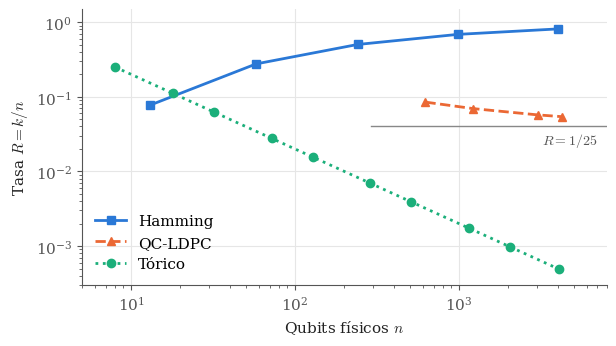

In [ ]:
fig, ax = plt.subplots(figsize=(6.3, 3.6))
for fam, filas in datos.items():
    n = [f[0] for f in filas]; R = [f[1] / f[0] for f in filas]
    ax.plot(n, R, label=fam, linewidth=2, markersize=6, **estilo[fam])
ax.axhline(1 / 25, xmin=0.55, **REF)
ax.text(7000, 1 / 25 / 1.15, r"$R=1/25$", ha="right", va="top", color="#555555", fontsize=10)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(5, 8000); ax.set_ylim(3e-4, 1.5)
ax.set_xlabel(r"Qubits físicos $n$"); ax.set_ylabel(r"Tasa $R=k/n$")
ax.grid(True, which="major", color="#e6e6e6", linewidth=0.8)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("figura_tasa.pdf")
plt.show()

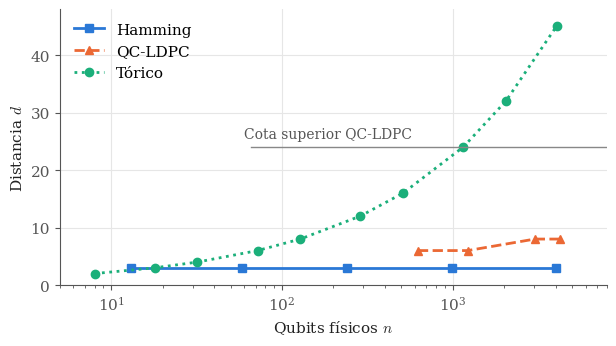

In [ ]:
fig, ax = plt.subplots(figsize=(6.3, 3.6))
for fam, filas in datos.items():
    n = [f[0] for f in filas]; d = [f[2] for f in filas]
    ax.plot(n, d, label=fam, linewidth=2, markersize=6, **estilo[fam])
ax.axhline(24, xmin=0.35, **REF)
ax.text(60, 25, "Cota superior QC-LDPC", ha="left", va="bottom", color="#555555", fontsize=10)
ax.set_xscale("log")
ax.set_xlim(5, 8000); ax.set_ylim(0, 48)
ax.set_xlabel(r"Qubits físicos $n$"); ax.set_ylabel(r"Distancia $d$")
ax.grid(True, which="major", color="#e6e6e6", linewidth=0.8)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figura_distancia.pdf")
plt.show()

## 5. Cotas cuánticas (sección 6.5)
### 5.1 Cota de Singleton cuántica: $k \le n-2d+2$

In [ ]:
filas = []
for fam, res in (("Hamming", res_hamming), ("QC-LDPC", res_qc)):
    for par, P in res.items():
        cota = P["N"] - 2 * P["D"] + 2
        assert P["K"] <= cota
        filas.append({"Familia": fam, "Parámetro": par, "Código": f"[[{P['N']},{P['K']},{P['D']}]]",
                      "n-2d+2": cota, "k / (n-2d+2)": round(P["K"] / cota, 3)})
tabla_singleton = pd.DataFrame(filas)
tabla_singleton

,Familia,Parámetro,Código,n-2d+2,k / (n-2d+2)
0,Hamming,2,"[[13,1,3]]",9,0.111
1,Hamming,3,"[[58,16,3]]",54,0.296
2,Hamming,4,"[[241,121,3]]",237,0.511
3,Hamming,5,"[[986,676,3]]",982,0.688
4,Hamming,6,"[[4005,3249,3]]",4001,0.812
5,QC-LDPC,5,"[[625,53,6]]",615,0.086
6,QC-LDPC,7,"[[1225,85,6]]",1215,0.070
7,QC-LDPC,11,"[[3025,173,8]]",3011,0.057
8,QC-LDPC,13,"[[4225,229,8]]",4211,0.054


Todos los códigos cumplen la cota. El más cercano es Hamming con $r=6$ ($3249$ frente a $4001$); para $p=5$ la cota permite $615$ qubits lógicos y el código codifica $53$.

### 5.2 Cota de Bravyi–Poulin–Terhal: $kd^2 \le c\,n$
Se calcula $kd^2/n$. Para el código tórico vale exactamente 1; en la familia de Hamming vale $9R$ y se aproxima a 9; en la familia QC-LDPC se mantiene entre 2,5 y 3,7. En ninguna familia crece con $n$.

In [ ]:
for fam, filas in datos.items():
    print(f"{fam:8s} kd^2/n:", [round(k * d**2 / n, 2) for n, k, d in filas])

assert all(abs(k * d**2 / n - 1) < 1e-12 for n, k, d in datos["Tórico"])
assert all(abs(k * d**2 / n - 9 * k / n) < 1e-12 for n, k, d in datos["Hamming"])
assert all(2.5 <= round(k * d**2 / n, 2) <= 3.7 for n, k, d in datos["QC-LDPC"])   # valores redondeados del texto

Hamming  kd^2/n: [0.69, 2.48, 4.52, 6.17, 7.3]
QC-LDPC  kd^2/n: [3.05, 2.5, 3.66, 3.47]
Tórico   kd^2/n: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 6. Códigos de la literatura (sección 6.6)
### 6.1 Código de Hamming cuántico
Para $r\ge 3$ el código de Hamming contiene a su dual ($H_rH_r^T=0$), de modo que define un código CSS con parámetros $[[2^r-1,\,2^r-1-2r,\,3]]$; para $r=3$ es el código de Steane $[[7,1,3]]$. Sus generadores son las filas de $H_r$, de peso $2^{r-1}$.

In [ ]:
filas = []
for r in range(3, 9):
    H = matriz_hamming(r)
    assert not ((H.astype(int) @ H.T.astype(int)) % 2).any()      # contiene a su dual
    n, k = 2**r - 1, 2**r - 1 - 2 * r
    assert k == n - 2 * rango_f2(H)                                # k = n - rank(H_X) - rank(H_Z)
    filas.append({"r": r, "Código": f"[[{n},{k},3]]", "R": round(k / n, 3),
                  "kd^2/n": round(9 * k / n, 2), "Peso": int(H.sum(axis=1).max())})
tabla_css_hamming = pd.DataFrame(filas)
tabla_css_hamming

,r,Código,R,kd^2/n,Peso
0,3,"[[7,1,3]]",0.143,1.29,4
1,4,"[[15,7,3]]",0.467,4.20,8
2,5,"[[31,21,3]]",0.677,6.10,16
3,6,"[[63,51,3]]",0.810,7.29,32
4,7,"[[127,113,3]]",0.890,8.01,64
5,8,"[[255,239,3]]",0.937,8.44,128


In [ ]:
assert filas[0]["Código"] == "[[7,1,3]]"                          # código de Steane
print("Comparación a tamaño similar (tabla 6.4):")
print(f"  HGP Hamming r=4: [[241,121,3]], peso {res_hamming[4]['peso_min']} a {res_hamming[4]['peso_max']}")
print(f"  Hamming cuántico r=8: {filas[-1]['Código']}, peso {filas[-1]['Peso']}")

Comparación a tamaño similar (tabla 6.4):
  HGP Hamming r=4: [[241,121,3]], peso 9 a 12
  Hamming cuántico r=8: [[255,239,3]], peso 128


### 6.2 Cuadro comparativo (cuadro 6.4)
Los parámetros del código bicicleta bivariado $[[288,12,18]]$ (generadores de peso 6) se toman de Bravyi *et al.* (2024); no se calculan aquí.

In [ ]:
comparacion = [
    ("Tórico, L=12",        "Kitaev",        288,   2, 12, "4"),
    ("HGP Hamming, r=4",    "Este trabajo",  res_hamming[4]["N"], res_hamming[4]["K"], res_hamming[4]["D"], "9 a 12"),
    ("CSS Hamming, r=8",    "Steane",        255, 239,  3, "128"),
    ("HGP QC-LDPC, p=5",    "Este trabajo",  res_qc[5]["N"], res_qc[5]["K"], res_qc[5]["D"], "7"),
    ("Bicicleta bivariado", "Bravyi et al.", 288,  12, 18, "6"),
]
tabla_comparacion = pd.DataFrame([{
    "Código": c, "Origen": o, "Parámetros": f"[[{n},{k},{d}]]",
    "R": round(k / n, 3), "kd^2/n": round(k * d**2 / n, 2), "Peso": w} for c, o, n, k, d, w in comparacion])
tabla_comparacion

,Código,Origen,Parámetros,R,kd^2/n,Peso
0,"Tórico, L=12",Kitaev,"[[288,2,12]]",0.007,1.00,4
1,"HGP Hamming, r=4",Este trabajo,"[[241,121,3]]",0.502,4.52,9 a 12
2,"CSS Hamming, r=8",Steane,"[[255,239,3]]",0.937,8.44,128
3,"HGP QC-LDPC, p=5",Este trabajo,"[[625,53,6]]",0.085,3.05,7
4,Bicicleta bivariado,Bravyi et al.,"[[288,12,18]]",0.042,13.50,6


### 6.3 Comparación con copias (tabla 6.5)
$m$ copias de un código $[[n,k,d]]$ forman un código $[[mn,\,mk,\,d]]$. Se busca la menor cantidad de copias que protege al menos 53 qubits lógicos con distancia 6 (los 53 del código QC-LDPC con $p=5$).

In [ ]:
def copias(n, k, d, k_objetivo):
    m = -(-k_objetivo // k)               # menor m con m*k >= k_objetivo
    return m, (m * n, m * k, d)

k_obj = res_qc[5]["K"]                     # 53 qubits lógicos con distancia 6
opciones = [("Bicicleta bivariado [[72,12,6]]", (72, 12, 6)),
            ("HGP QC-LDPC, p=5", (res_qc[5]["N"], res_qc[5]["K"], res_qc[5]["D"])),
            ("Tórico [[72,2,6]], L=6", (2 * 6**2, 2, 6))]
filas = []
for nombre, (n, k, d) in opciones:
    m, (N, K, D) = copias(n, k, d, k_obj)
    filas.append({"Opción": nombre, "Copias": m, "Código resultante": f"[[{N},{K},{D}]]",
                  "Qubits físicos": N, "Qubits físicos por qubit lógico": round(N / K, 1)})
tabla_copias = pd.DataFrame(filas)
tabla_copias

,Opción,Copias,Código resultante,Qubits físicos,Qubits físicos por qubit lógico
0,"Bicicleta bivariado [[72,12,6]]",5,"[[360,60,6]]",360,6.0
1,"HGP QC-LDPC, p=5",1,"[[625,53,6]]",625,11.8
2,"Tórico [[72,2,6]], L=6",27,"[[1944,54,6]]",1944,36.0


In [ ]:
assert list(tabla_copias["Copias"]) == [5, 1, 27]
assert list(tabla_copias["Qubits físicos"]) == [360, 625, 1944]
assert list(tabla_copias["Qubits físicos por qubit lógico"]) == [6.0, 11.8, 36.0]   # 6, unos 12 y 36
print(f"QC-LDPC / tórico    = {625 / 1944:.2f}  (cerca de la tercera parte)")
print(f"QC-LDPC / bicicleta = {625 / 360:.2f}  (casi el doble)")

QC-LDPC / tórico    = 0.32  (cerca de la tercera parte)
QC-LDPC / bicicleta = 1.74  (casi el doble)
